<img src='http://drive.google.com/uc?export=view&id=1UAsSD6z0wK4UJjjzBhDEIlSZnELLmeeb'>

# <font color='lightblue'>Answering Questions</font>

In this project you will use all you learnt about in the class to answer a question. Imagine you are part of a team and you have been assigned a question to answer, build a notebook that you would be able to share with your team that shows what you found.

In this project you will:

1.  Introduce your question of interest
2.  Make sure your reader knows enough about the data
3.  Wrangle and preprocess your data so that a team mate can reproduce your work
4.  Build and test a model that can provide insight into your question
5.  Interpret your model results
6.  Answer your question



Note: Marks will be awarded for clarity, organization, and succinctness. I.e., try to point out only the important parts in a well-organized easy to follow manner. (Marks: 3)

### This project was completed by:


*   Ahmed Muhammad
*   Joy Umejiego
*   Sandra Igboanugo

## <font color='lightblue'>1. Ask a question </font>

**Q1**: Layout your question of interest. Remember to state your question as clearly and simply as you can (Mark 1), and what your ideal outcome would be (Marks 1).

**Q2**: Identify and describe what data sources you'll use (Marks 1). Make sure to talk about one of the following: data accuracy, reliability, validity, or sample selection. (Marks: 1)

**Q3**: Layout what kind of ML problem you are facing and what kind of model you'll use to answer it (eg., is it unsupervised or supervised learning, and is it classification or regression). Make sure to say why. (Marks 1)

## <font color='lightblue'>2. Data understanding, exploration, and visualization </font>

**Action**: While above you gave an overview of the dataset(s) that will be used, here make sure that the reader understands the important details of the data. E.g., show a figure or descriptive statistic and explain why the reader should know about this, i.e., how will it help your reader understand your analysis? (Marks: 2)

## Data Overview

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.inspection import permutation_importance

import kagglehub
import os

path = kagglehub.dataset_download("redwankarimsony/heart-disease-data")
csv_path = os.path.join(path, "heart_disease_uci.csv")
health_data_df = pd.read_csv(csv_path)

print(health_data_df.shape)
health_data_df.head(4)

Using Colab cache for faster access to the 'heart-disease-data' dataset.
(920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0


## Data Cleaning & Exploration

In [ ]:
# Fix 1: impossible values (0 cholesterol, 0 blood pressure) are placeholders, so mark them as missing
health_data_df.loc[health_data_df['chol'] == 0, 'chol'] = np.nan
health_data_df.loc[health_data_df['trestbps'] == 0, 'trestbps'] = np.nan
# Fix 2: clearer column name
health_data_df.rename(columns={'dataset': 'origin'}, inplace=True)
# New yes/no label: 0 = no disease, 1 = disease of any severity (num 1-4)
health_data_df['diseased'] = (health_data_df['num'] != 0).astype(int)

# % of missing values in each column
print("% of missing values in each column:")
(health_data_df.isna().mean() * 100).round(1).sort_values(ascending=False)

% of missing values in each column:


,0
ca,66.4
thal,52.8
slope,33.6
chol,22.0
fbs,9.8
oldpeak,6.7
trestbps,6.5
exang,6.0
thalch,6.0
restecg,0.2


In [ ]:
# % missing in the four worst columns, split by hospital
(health_data_df.groupby('origin')[['ca', 'thal', 'slope', 'chol']].apply(lambda g: g.isna().mean() * 100)).round(1)

,ca,thal,slope,chol
origin,,,,
Cleveland,1.6,1.0,0.3,0.0
Hungary,99.0,90.4,64.5,7.8
Switzerland,95.9,42.3,13.8,100.0
VA Long Beach,99.0,83.0,51.0,28.0


## Summary Statistics

In [ ]:
# Patients with no gaps in the measurements we use (the same 766 patients we keep in Section 3)
plot_cols = ['age', 'sex', 'cp', 'trestbps', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak']
explore_df = health_data_df.dropna(subset=plot_cols).copy()

key_vars = ['age', 'trestbps', 'thalch', 'oldpeak']
print(explore_df[key_vars].describe().round(2))

          age  trestbps  thalch  oldpeak
count  766.00    766.00  766.00   766.00
mean    53.01    132.95  138.69     0.88
std      9.45     17.97   25.79     1.08
min     28.00     92.00   60.00    -1.00
25%     46.00    120.00  120.00     0.00
50%     54.00    130.00  140.00     0.50
75%     59.00    140.00  159.00     1.50
max     77.00    200.00  202.00     6.20


In [ ]:
# Average of each key measurement for patients without (0) and with (1) heart disease
explore_df.groupby('diseased')[key_vars].mean().round(2)

,age,trestbps,thalch,oldpeak
diseased,,,,
0,50.14,130.00,149.01,0.42
1,55.76,135.79,128.79,1.33


## Data Visualization

### Severity -> Yes/No

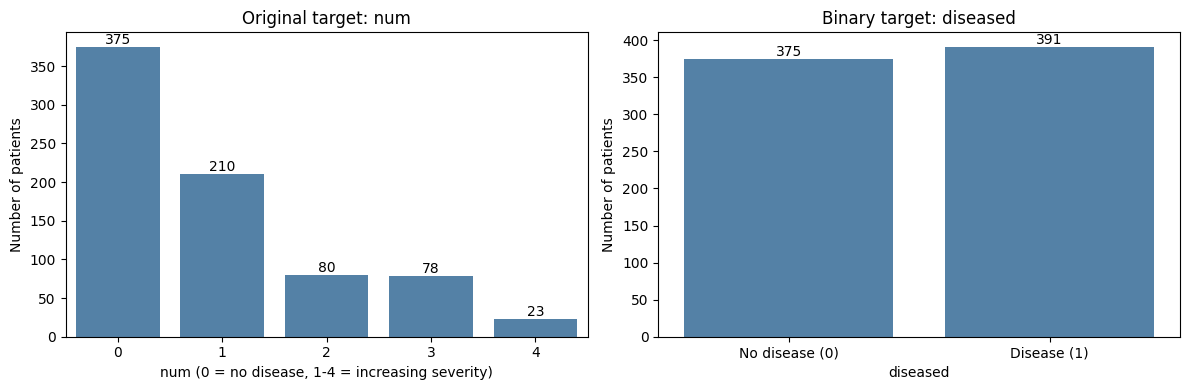

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=explore_df, x='num', color='steelblue', ax=axes[0])
axes[0].bar_label(axes[0].containers[0])
axes[0].set_xlabel('num (0 = no disease, 1-4 = increasing severity)')
axes[0].set_ylabel('Number of patients')
axes[0].set_title('Original target: num')

sns.countplot(data=explore_df, x='diseased', color='steelblue', ax=axes[1])
axes[1].bar_label(axes[1].containers[0])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No disease (0)', 'Disease (1)'])
axes[1].set_xlabel('diseased')
axes[1].set_ylabel('Number of patients')
axes[1].set_title('Binary target: diseased')

plt.tight_layout()
plt.show()

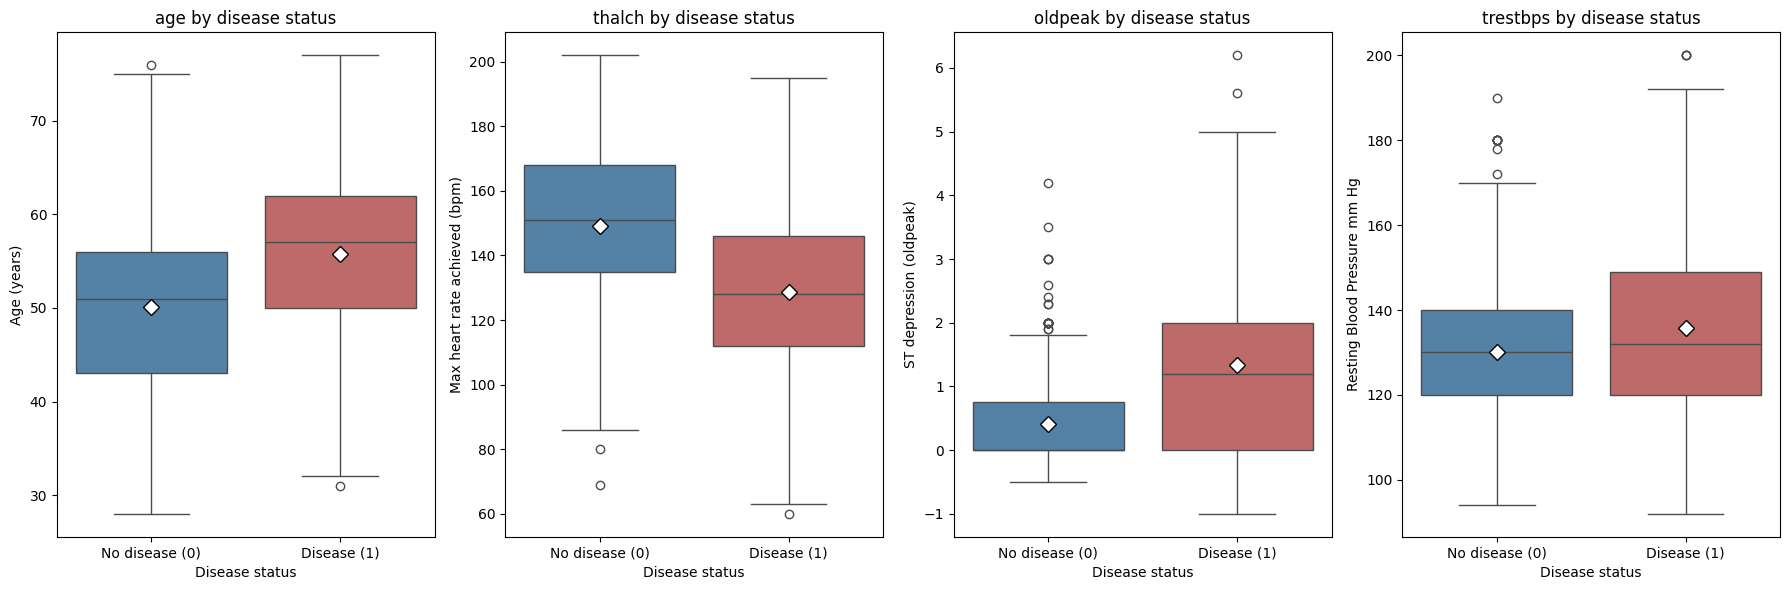

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 6))

box_vars = {'age': 'Age (years)',
            'thalch': 'Max heart rate achieved (bpm)',
            'oldpeak': 'ST depression (oldpeak)',
            'trestbps': 'Resting Blood Pressure mm Hg'}

for ax, (col, label) in zip(axes, box_vars.items()):
    sns.boxplot(data=explore_df, x='diseased', y=col, hue='diseased', legend=False,
                palette=['steelblue', 'indianred'], ax=ax, showmeans=True,
                meanprops={"marker":"D", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"})
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No disease (0)', 'Disease (1)'])
    ax.set_xlabel('Disease status')
    ax.set_ylabel(label)
    ax.set_title(f'{col} by disease status')

plt.tight_layout()
plt.show()

### The percentage of patients in that group who have heart disease

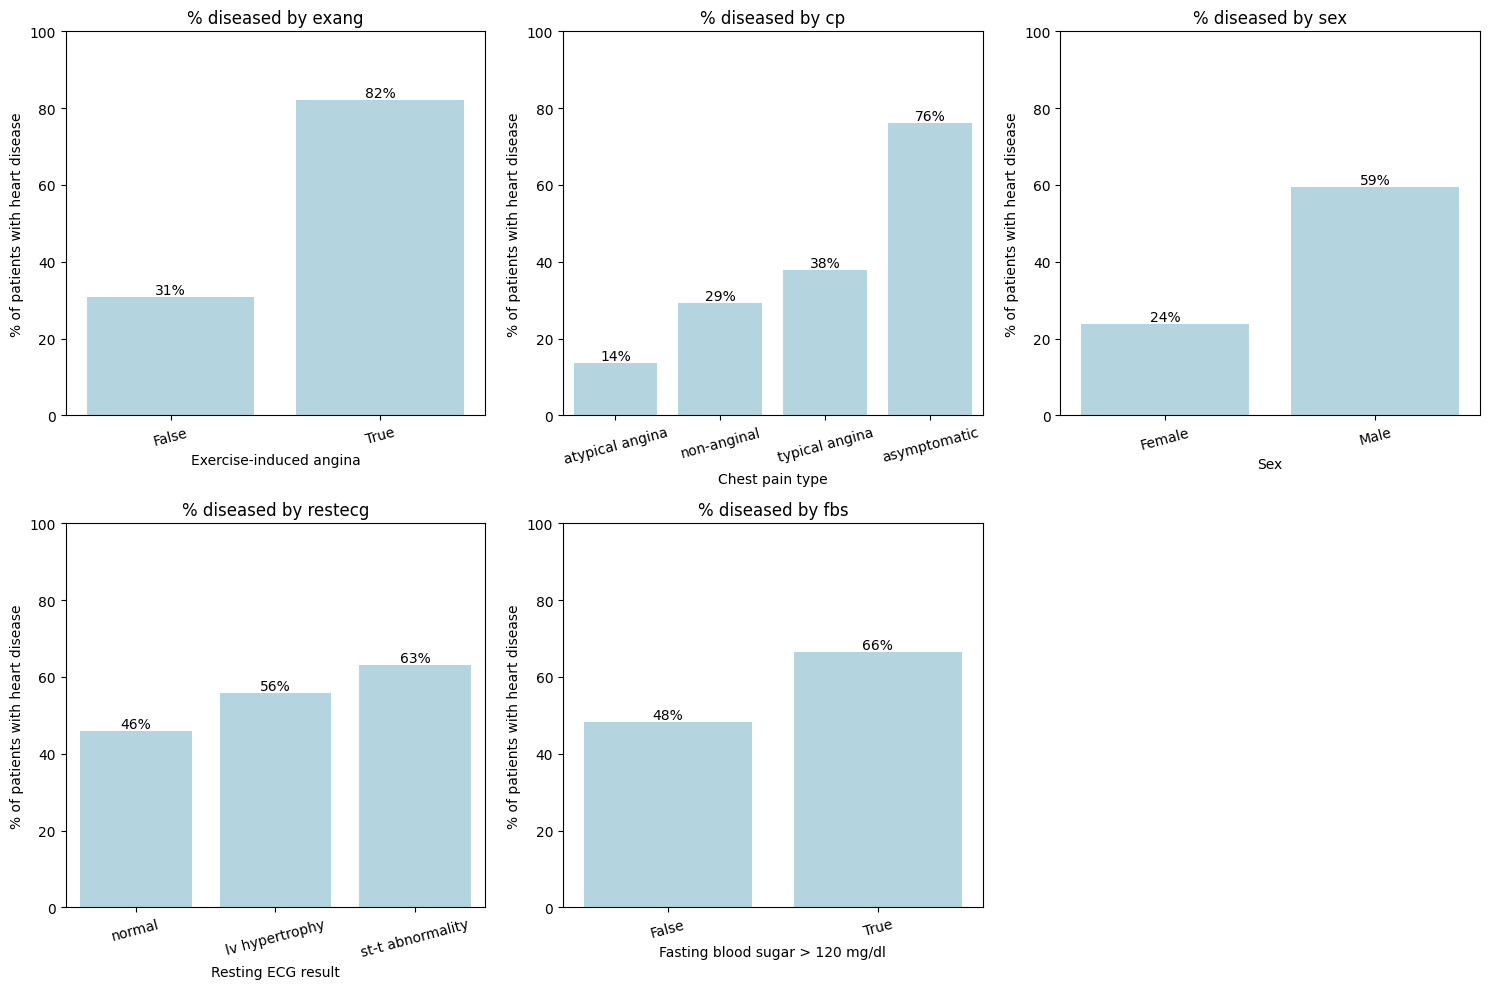

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

cat_vars = {'exang': 'Exercise-induced angina',
            'cp': 'Chest pain type',
            'sex': 'Sex',
            'restecg': 'Resting ECG result',
            'fbs': 'Fasting blood sugar > 120 mg/dl'}

for ax, (col, label) in zip(axes.flatten(), cat_vars.items()):
  #Here we are just dividing the given column by the diseased status, and then finding the mean of diseased vs no diseaesed
    disease_rate = (explore_df.groupby(col)['diseased'].mean() * 100).sort_values()
    sns.barplot(x=disease_rate.index.astype(str), y=disease_rate.values, color='lightblue', ax=ax)
    ax.bar_label(ax.containers[0], fmt='%.0f%%') # writes the % on top of each bar
    ax.set_xlabel(label)
    ax.set_ylabel('% of patients with heart disease')
    ax.set_ylim(0, 100)
    ax.set_title(f'% diseased by {col}')
    ax.tick_params(axis='x', rotation=15)

axes.flatten()[-1].axis('off') # only 5 variables, so we hide the empty 6th panel

plt.tight_layout()
plt.show()

### Correlation

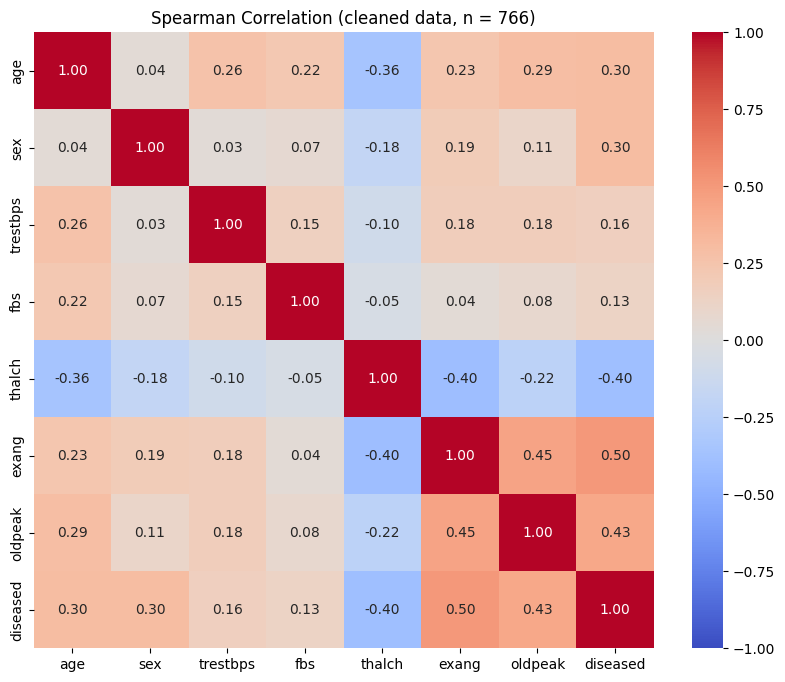

In [ ]:
corr_vars = ['age', 'sex', 'trestbps', 'fbs', 'thalch', 'exang', 'oldpeak', 'diseased']

# sex, fbs and exang converted to 1/0 just for the correlation
corr_matrix = (
    explore_df[corr_vars]
    .assign(sex=(explore_df['sex'] == 'Male').astype(int),
            fbs=(explore_df['fbs'] == True).astype(int),
            exang=(explore_df['exang'] == True).astype(int))
    .corr(method='spearman')
)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title(f"Spearman Correlation (cleaned data, n = {len(explore_df)})")
plt.show()

## <font color='lightblue'>3. Data wrangling and preprocessing </font>

**Action**: Layout all your data wrangling and preprocessing steps so that a reader will understand why you took each step, and would be able to reproduce your steps. (Marks: 3)

In [ ]:
# Step 3: drop the mostly-missing columns, then drop any remaining rows with gaps
health_clean_df = health_data_df.drop(['ca', 'thal', 'slope', 'chol'], axis=1)
health_clean_df = health_clean_df.dropna(how='any')

print(health_clean_df.shape)
print(health_clean_df.isna().sum().sum(), "missing values left")

print("\nMissing Values per column:\n", health_clean_df.isna().sum())

(766, 13)
0 missing values left

Missing Values per column:
 id          0
age         0
sex         0
origin      0
cp          0
trestbps    0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
num         0
diseased    0
dtype: int64


In [ ]:
# Check that dropping rows didn't leave mostly sick or mostly healthy patients
health_clean_df['diseased'].value_counts(normalize=True)*100

,proportion
diseased,
1,51.044386
0,48.955614


In [ ]:
health_model_df = health_clean_df.copy()

# Step 1: binary variables to 1/0
health_model_df['sex'] = (health_model_df['sex'] == 'Male').astype(int)   # Male = 1, Female = 0
health_model_df['fbs'] = (health_model_df['fbs'] == True).astype(int)     # True = 1, False = 0
health_model_df['exang'] = (health_model_df['exang'] == True).astype(int) # True = 1, False = 0

# Step 2: one-hot encode cp and restecg
category_cols = ['cp', 'restecg']
df_cat = pd.get_dummies(health_model_df[category_cols], dtype=int)

health_model_df = pd.concat([health_model_df, df_cat], axis=1)
health_model_df.drop(category_cols, axis=1, inplace=True)

health_model_df.head()

,id,age,sex,origin,trestbps,fbs,thalch,exang,oldpeak,num,diseased,cp_asymptomatic,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality
0,1,63,1,Cleveland,145.0,1,150.0,0,2.3,0,0,0,0,0,1,1,0,0
1,2,67,1,Cleveland,160.0,0,108.0,1,1.5,2,1,1,0,0,0,1,0,0
2,3,67,1,Cleveland,120.0,0,129.0,1,2.6,1,1,1,0,0,0,1,0,0
3,4,37,1,Cleveland,130.0,0,187.0,0,3.5,0,0,0,0,1,0,0,1,0
4,5,41,0,Cleveland,130.0,0,172.0,0,1.4,0,0,0,1,0,0,1,0,0


## <font color='lightblue'>4. Build and test a model</font>

**Action:** Use your training dataset to build a model with the goal addressing your question of interest. (Marks: 2)

In [ ]:
X = health_model_df.drop(['id', 'origin', 'num', 'diseased'], axis=1)
y = health_model_df['diseased']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

print("Predictors:", list(X.columns), "\n")
print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)
print(f"% diseased in training: {y_train.mean()*100:.1f}%") #.1f means 1 decimal place, floating value!
print(f"% diseased in testing:  {y_test.mean()*100:.1f}%")

Predictors: ['age', 'sex', 'trestbps', 'fbs', 'thalch', 'exang', 'oldpeak', 'cp_asymptomatic', 'cp_atypical angina', 'cp_non-anginal', 'cp_typical angina', 'restecg_lv hypertrophy', 'restecg_normal', 'restecg_st-t abnormality'] 

Training set: (612, 14)
Testing set:  (154, 14)
% diseased in training: 51.0%
% diseased in testing:  51.3%


**Q4**: Measure the performance of your model, and describe how well your model generalizes to new data (Marks: 2)

In [ ]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

print("Training accuracy:", accuracy_score(y_train, model.predict(X_train)))
print("Tree depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())

Training accuracy: 1.0
Tree depth: 15
Number of leaves: 139


### Deciding the Depth

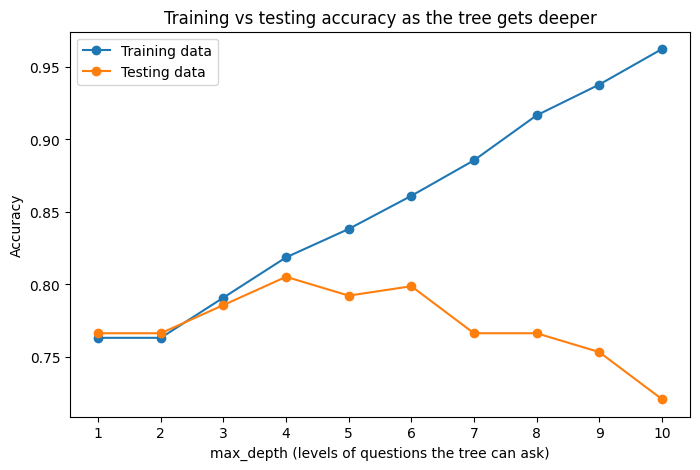

,max_depth,train_accuracy,test_accuracy
0,1,0.763,0.766
1,2,0.763,0.766
2,3,0.791,0.786
3,4,0.819,0.805
4,5,0.838,0.792
5,6,0.861,0.799
6,7,0.886,0.766
7,8,0.917,0.766
8,9,0.938,0.753
9,10,0.962,0.721


In [ ]:
depth_results = []

for depth in range(1, 11):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    depth_results.append({'max_depth': depth,
                          'train_accuracy': accuracy_score(y_train, tree.predict(X_train)),
                          'test_accuracy': accuracy_score(y_test, tree.predict(X_test))})

depth_df = pd.DataFrame(depth_results)

plt.figure(figsize=(8, 5))
plt.plot(depth_df['max_depth'], depth_df['train_accuracy'], marker='o', label='Training data')
plt.plot(depth_df['max_depth'], depth_df['test_accuracy'], marker='o', label='Testing data')
plt.xlabel('max_depth (levels of questions the tree can ask)')
plt.ylabel('Accuracy')
plt.title('Training vs testing accuracy as the tree gets deeper')
plt.xticks(range(1, 11))
plt.legend()
plt.show()

depth_df.round(3)

### Decision Tree

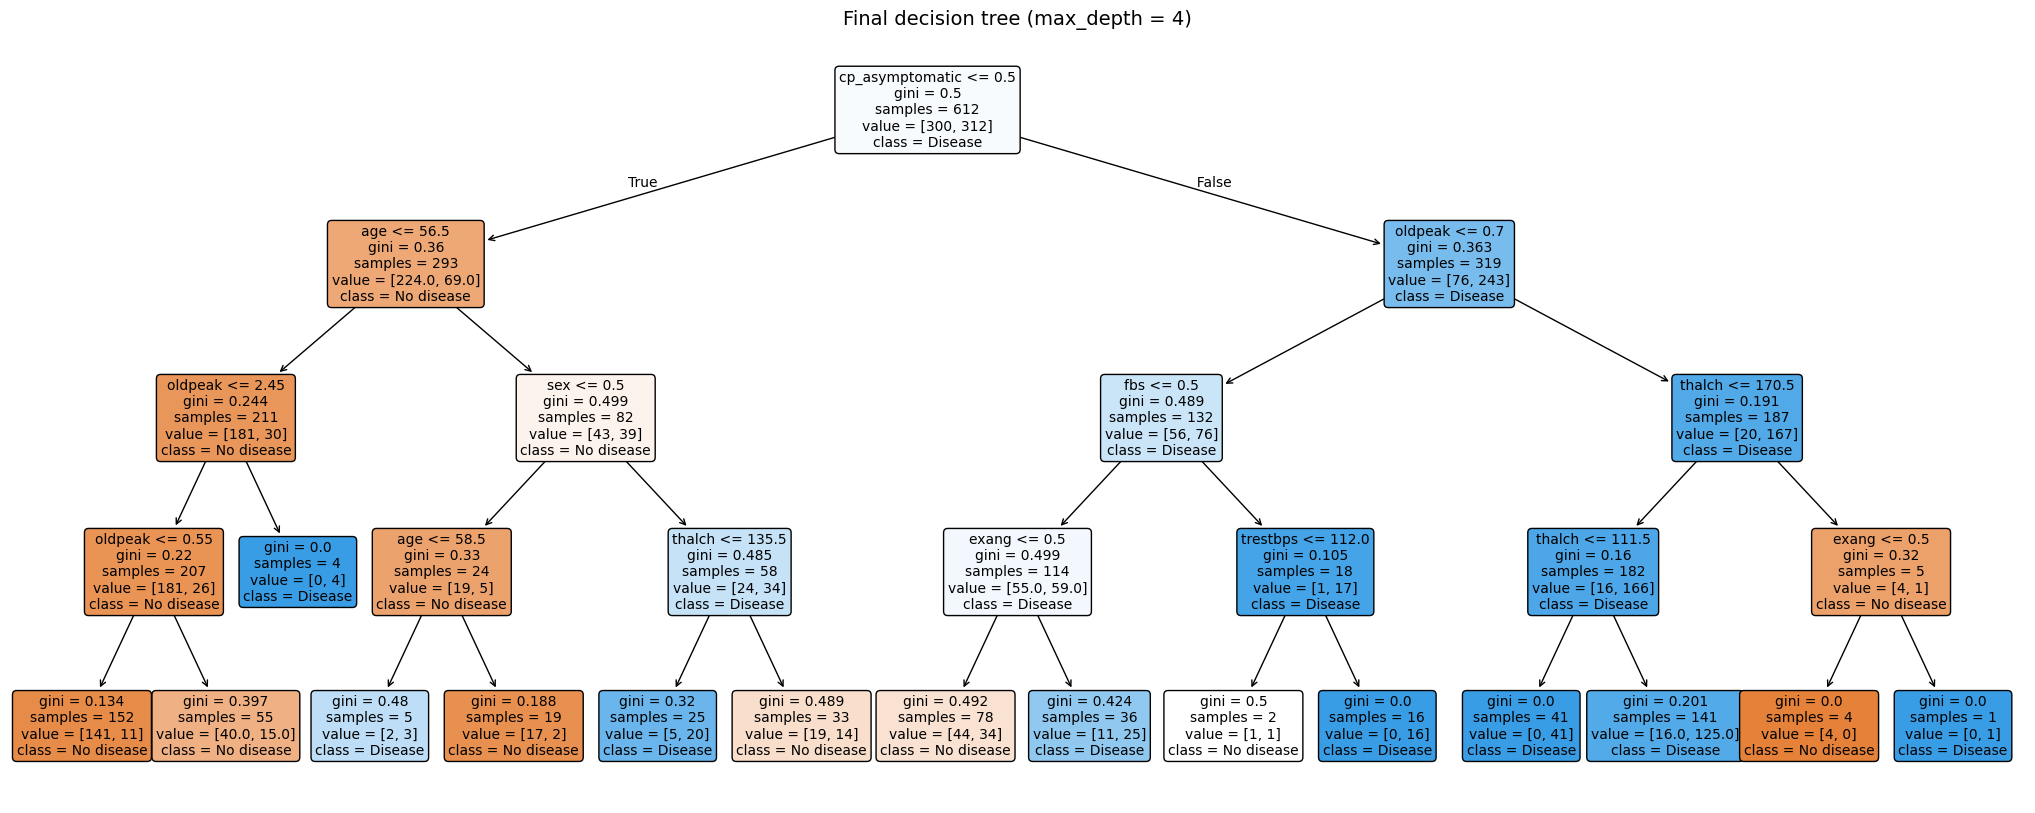

In [ ]:
tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)

plt.figure(figsize=(26, 10))
plot_tree(tree_model, feature_names=list(X.columns), class_names=['No disease', 'Disease'],
          filled=True, rounded=True, fontsize=10)
plt.title('Final decision tree (max_depth = 4)', fontsize=14)
plt.show()

In [ ]:
y_num_train = health_model_df.loc[X_train.index, 'num']
y_num_test = health_model_df.loc[X_test.index, 'num']

num_model = DecisionTreeClassifier(max_depth=4, random_state=42)
num_model.fit(X_train, y_num_train)

print(f"num (0-4) test accuracy: {accuracy_score(y_num_test, num_model.predict(X_test)):.3f}")

num (0-4) test accuracy: 0.571


In [ ]:
y_pred = tree_model.predict(X_test)

model_acc = accuracy_score(y_test, y_pred)
model_prec = precision_score(y_test, y_pred)
model_rec = recall_score(y_test, y_pred)

baseline_class = y_test.value_counts().idxmax() # most common class in the test set (1 = disease)
baseline_acc = y_test.value_counts(normalize=True).max()

print(f"baseline accuracy (always '{['no disease', 'disease'][baseline_class]}'): {baseline_acc:.2f}")
print(f"accuracy:  {model_acc:.2f}")
print(f"precision: {model_prec:.2f}")
print(f"recall:    {model_rec:.2f}")

baseline accuracy (always 'disease'): 0.51
accuracy:  0.81
precision: 0.80
recall:    0.82


### Confusion Matrix

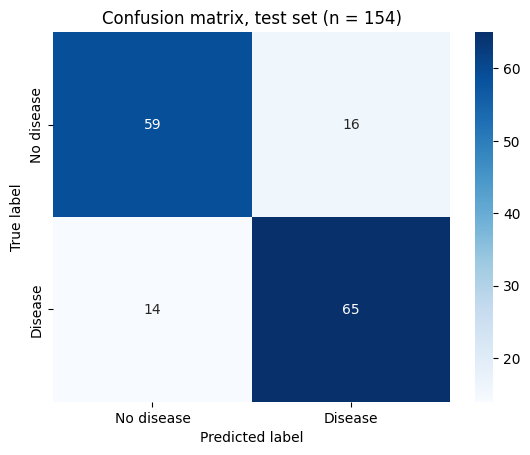

In [ ]:
cm_tree = confusion_matrix(y_test, y_pred)

sns.heatmap(cm_tree, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No disease', 'Disease'], yticklabels=['No disease', 'Disease'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title(f'Confusion matrix, test set (n = {len(y_test)})')
plt.show()

In [ ]:
compare_df = pd.DataFrame({
    'model': ['Default tree (no depth limit)', 'Final tree (max_depth = 4)'],
    'train_accuracy': [accuracy_score(y_train, model.predict(X_train)), accuracy_score(y_train, tree_model.predict(X_train))],
    'test_accuracy': [accuracy_score(y_test, model.predict(X_test)), model_acc]
})

compare_df.round(3)

,model,train_accuracy,test_accuracy
0,Default tree (no depth limit),1.000,0.734
1,Final tree (max_depth = 4),0.819,0.805


## <font color='lightblue'>5. Interpret your model</font>

**Q5**: Interpret your model results. E.g., what features contributed to your predictions, if possible, can you determine the sign and magnitude of the effect (Marks: 2).

### Performance of the Model

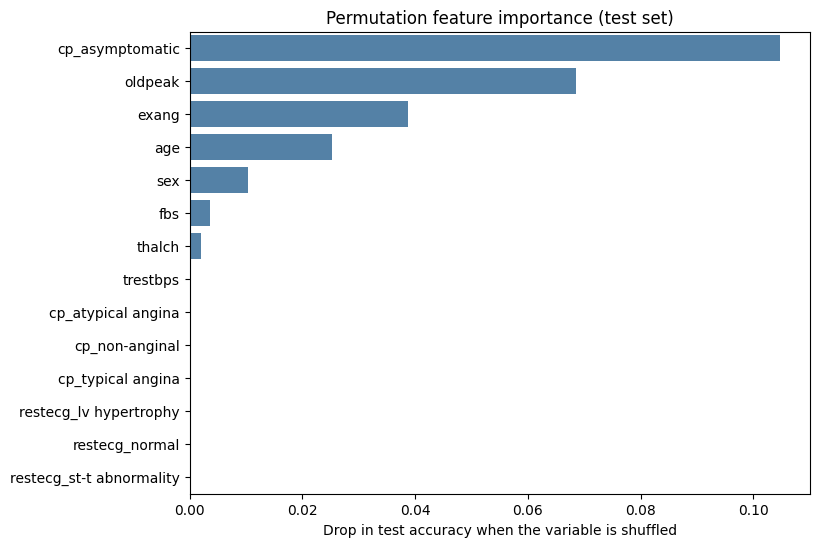

,feature,importance,sd
7,cp_asymptomatic,0.105,0.025
6,oldpeak,0.069,0.020
5,exang,0.039,0.012
0,age,0.025,0.016
1,sex,0.010,0.009
3,fbs,0.004,0.008
4,thalch,0.002,0.016
2,trestbps,0.000,0.004
8,cp_atypical angina,0.000,0.000
9,cp_non-anginal,0.000,0.000


In [ ]:
rel_impo = permutation_importance(tree_model, X_test, y_test, n_repeats=30, random_state=42)

df_feature_importance = pd.DataFrame({'feature': X_test.columns,
'importance': rel_impo.importances_mean,
'sd': rel_impo.importances_std})
df_feature_importance.sort_values(by='importance', ascending=False, inplace=True)

plt.figure(figsize=(8, 6))
sns.barplot(data=df_feature_importance, y='feature', x='importance', color='steelblue')
plt.xlabel('Drop in test accuracy when the variable is shuffled')
plt.ylabel('')
plt.title('Permutation feature importance (test set)')
plt.show()

df_feature_importance.round(3)

## <font color='lightblue'>6. Answer your question</font>

**Q6:** Use your analysis above to answer your question of interest. Did you achieve your desired outcome, and what might the next steps be? Remember to write as though you are writing to team mates working on the same/similar problem. (Marks: 3)


Note: It is ok if your analysis doesn't provide a strong answer, you can point out where it failed. If anything you can cross the approach you took off the list of possible ways to tackle your question. I.e., you still made progress!